In [82]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from mpl_toolkits.mplot3d import Axes3D

# 1.資料清洗、去重、格式轉換

In [ ]:
# 1. 讀取資料表
sleeps = pd.read_csv('sleeps.csv')
levels_map = pd.read_csv('sleeps_levelsmap.csv')
spo2 = pd.read_csv('sleeps_sleepSpo2.csv')

# 2. 排序與去重：ID -> date -> summaryId -> startTimeInSeconds
# 根據建議，保留每一天最後一次上傳的 SummaryID (資料完整性最高)
sleeps_sorted = sleeps.sort_values(by=['_userId', 'date', 'summaryId', 'startTimeInSeconds'])
sleeps_cleaned = sleeps_sorted.groupby(['_userId', 'date']).tail(1).reset_index(drop=True)

# 過濾其他子表，確保僅包含保留下來的有效 SummaryID
valid_summary_ids = set(sleeps_cleaned['summaryId'])
levels_map_cleaned = levels_map[levels_map['summaryId'].isin(valid_summary_ids)].copy()
spo2_cleaned = spo2[spo2['summaryId'].isin(valid_summary_ids)].copy()

# 3. 定義日期轉換函數 (根據老師提供的 1900/1/1 基準公式)
def convert_to_datetime(s):
    # 計算 Excel 日期序號
    excel_date_num = (s + 8*3600)/86400 + (70*365 + 19)
    # 轉換為 pandas datetime (Excel 的 1900 起點在 pandas 中對應 1899-12-30)
    return pd.to_datetime(excel_date_num, unit='D', origin='1899-12-30')

# 4. 處理時間欄位
# 主表睡眠起始時間
sleeps_cleaned['converted_start_time'] = convert_to_datetime(sleeps_cleaned['startTimeInSeconds'])

# 睡眠階段變動表時間
levels_map_cleaned['converted_start_time'] = convert_to_datetime(levels_map_cleaned['startTimeInSeconds'])

# 血氧資料處理：需先與主表合併以取得該睡眠區間的 startTimeInSeconds 基點
spo2_processed = pd.merge(spo2_cleaned, sleeps_cleaned[['summaryId', 'startTimeInSeconds']], on='summaryId', how='left')
# 實際觀測秒數 = 區間起始秒數 + 內部位移秒數 (timeseconds)
spo2_processed['actualTimeInSeconds'] = spo2_processed['startTimeInSeconds'] + spo2_processed['timeseconds']
spo2_processed['converted_obs_time'] = convert_to_datetime(spo2_processed['actualTimeInSeconds'])

# 5. 輸出結果
sleeps_cleaned.to_csv('sleeps_final.csv', index=False)
spo2_processed.to_csv('spo2_with_timestamp.csv', index=False)


資料處理完成，已生成去重後的主表與帶有精確時間戳的血氧表。


In [84]:
# 定義老日期轉換函數 (基準 1900/1/1)
def convert_to_datetime(s):
    # 公式: (starttimeinsecond + 8*3600)/86400 + 70*365 + 19
    excel_date_num = (s + 8*3600)/86400 + (70*365 + 19)
    # 轉換為 pandas datetime
    return pd.to_datetime(excel_date_num, unit='D', origin='1899-12-30')

# 特徵工程：計算睡眠階段比例、生理指標聚合

In [85]:
# 計算血氧平均值並與主表合併
spo2_agg = spo2.groupby('summaryId')['SleepSpo2'].agg(['mean']).reset_index()
spo2_agg.columns = ['summaryId', 'avg_spo2']

df_model = pd.merge(sleeps_cleaned, spo2_agg, on='summaryId', how='inner')
df_model['deep_pct'] = df_model['deepSleepDurationInSeconds'] / df_model['durationInSeconds']
df_model['rem_pct'] = df_model['remSleepInSeconds'] / df_model['durationInSeconds']
df_model = df_model.dropna(subset=['avg_spo2', 'deep_pct', 'rem_pct'])

# 2. 交互作用回歸建模 (Regression with Interaction)

In [ ]:
drop_indices = [605, 160, 684]

# 確保只刪除還存在的 index (避免報錯)
existing_indices = [i for i in drop_indices if i in df_model.index]
df_final_clean = df_model.drop(existing_indices).copy()

print(f"已刪除索引: {existing_indices}")
print(f"清洗後資料剩餘筆數: {len(df_final_clean)}")

# 2. 重新跑最終模型
import statsmodels.formula.api as smf

final_model = smf.ols('avg_spo2 ~ deep_pct * rem_pct + durationInSeconds', data=df_final_clean).fit()
print(final_model.summary())

# 3. 檢查關鍵指標
pval = final_model.pvalues['deep_pct:rem_pct']
r2 = final_model.rsquared



已刪除索引: [605, 160, 684]
清洗後資料剩餘筆數: 817
                            OLS Regression Results                            
Dep. Variable:               avg_spo2   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     4.080
Date:                Sat, 27 Dec 2025   Prob (F-statistic):            0.00279
Time:                        19:31:39   Log-Likelihood:                -1733.5
No. Observations:                 817   AIC:                             3477.
Df Residuals:                     812   BIC:                             3501.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------


# 3. 模型診斷 (Model Diagnostics)

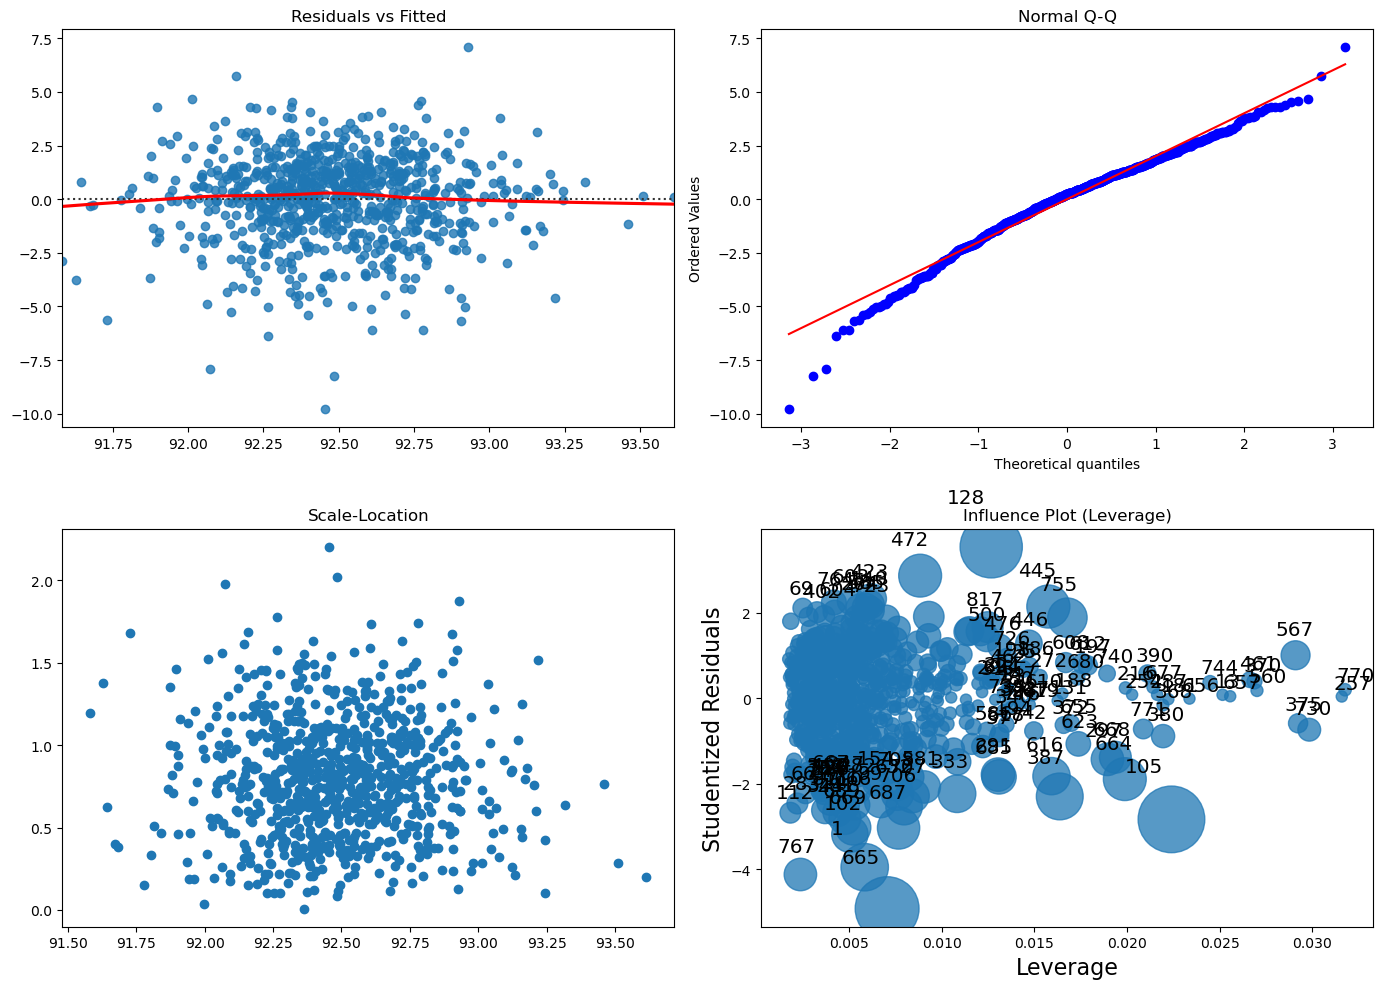

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) 殘差 vs 擬合值 (檢查線性與齊一性)
sns.residplot(x=final_model.fittedvalues, y=final_model.resid, lowess=True, ax=axes[0, 0], line_kws={'color': 'red'})
axes[0, 0].set_title('Residuals vs Fitted')

# (2) 常態 Q-Q 圖 (檢查殘差常態性)
stats.probplot(final_model.resid, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Normal Q-Q')

# (3) 標準化殘差平方根圖 (檢查變異數齊一性)
axes[1, 0].scatter(final_model.fittedvalues, np.sqrt(np.abs(final_model.get_influence().resid_studentized_internal)))
axes[1, 0].set_title('Scale-Location')

# (4) 影響力圖 (檢查離群值與槓桿值)
sm.graphics.influence_plot(final_model, criterion="cooks", ax=axes[1, 1])
axes[1, 1].set_title('Influence Plot (Leverage)')

plt.tight_layout()
plt.show()

# 4. 高維度視覺化 (High-Dimensional Visualization)

# --- (A) 交互作用項對血氧的整體影響圖 ---

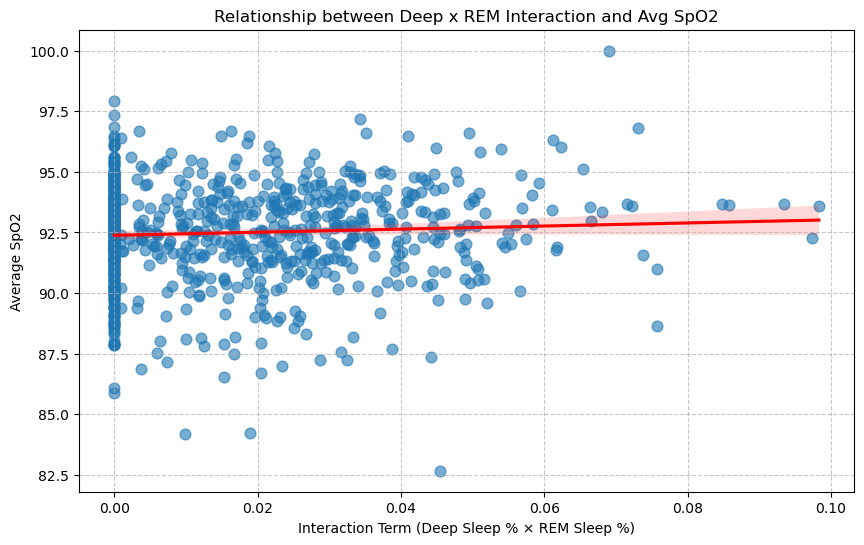

In [88]:
df_final_clean['interaction_term'] = df_final_clean['deep_pct'] * df_final_clean['rem_pct']

plt.figure(figsize=(10, 6))

sns.regplot(
    x='interaction_term',
    y='avg_spo2',
    data=df_final_clean,
    scatter_kws={'alpha': 0.6, 's': 60}, 
    line_kws={'color': 'red'} 
)


plt.title('Relationship between Deep x REM Interaction and Avg SpO2')
plt.xlabel('Interaction Term (Deep Sleep % × REM Sleep %)')
plt.ylabel('Average SpO2')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

# --- (B) 交互作用調節效果三維空間圖 ---

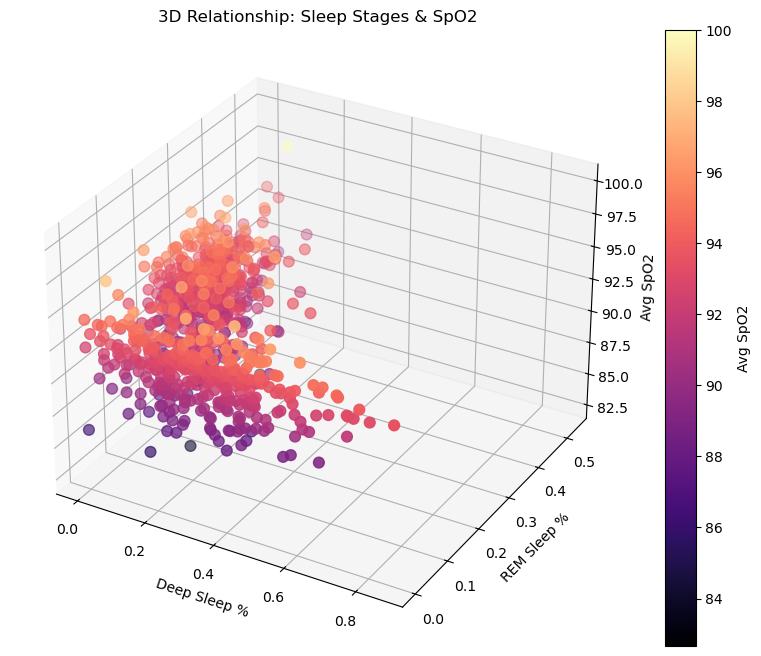

In [89]:
fig_3d = plt.figure(figsize=(10, 8))
ax = fig_3d.add_subplot(111, projection='3d')
sc = ax.scatter(df_final_clean['deep_pct'], df_final_clean['rem_pct'], df_final_clean['avg_spo2'],
                c=df_final_clean['avg_spo2'], cmap='magma', s=60)

ax.set_xlabel('Deep Sleep %')
ax.set_ylabel('REM Sleep %')
ax.set_zlabel('Avg SpO2')
plt.colorbar(sc, label='Avg SpO2')
plt.title('3D Relationship: Sleep Stages & SpO2')
plt.show()

上圖展示了深層睡眠比例 (X軸)、REM 睡眠比例 (Y軸) 與平均血氧飽和度 (Z軸/顏色) 的三維關係。
* **顏色意涵**：亮黃色代表高血氧 (>95%)，深紫色代表低血氧 (<90%)。
* **空間趨勢**：可以觀察到亮黃色的數據點主要集中在圖形的**「遠端右上角」**，即深層睡眠與 REM 睡眠**同時較高**的區域。反之，當任一睡眠階段比例過低時，數據點多呈現紫色或暗紅色。此視覺化結果直觀地佐證了兩者對血氧提升的協同效應。

# --- (C) 交互作用調節效果二維圖 ---
# 將 REM 比例依中位數分為高低兩組，觀察深層睡眠對血氧影響的差異

<Figure size 1000x600 with 0 Axes>

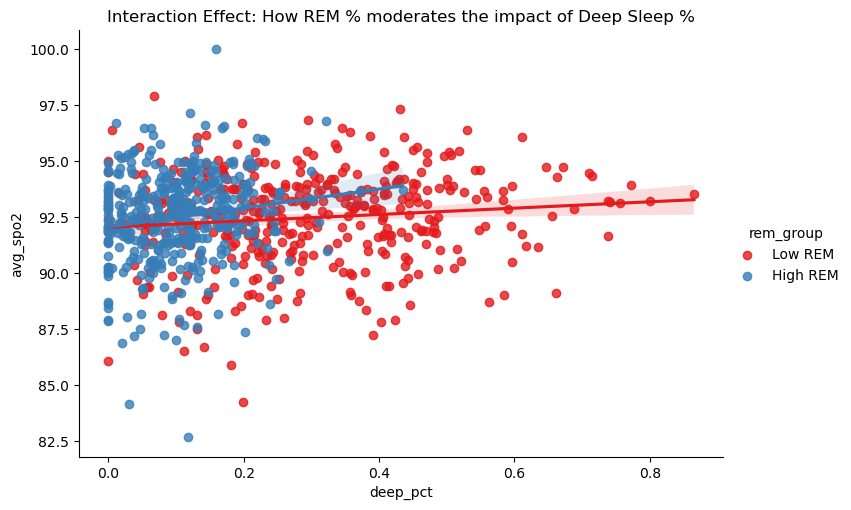

In [90]:
df_final_clean['rem_level'] = df_final_clean['rem_pct'] > df_final_clean['rem_pct'].median()
df_final_clean['rem_group'] = df_final_clean['rem_level'].map({
    False: 'Low REM', 
    True: 'High REM'
})

plt.figure(figsize=(10, 6))
sns.lmplot(x='deep_pct', y='avg_spo2', hue='rem_group', data=df_final_clean, 
           palette='Set1', aspect=1.5, legend=True,
           hue_order=['Low REM', 'High REM']) 

plt.title('Interaction Effect: How REM % moderates the impact of Deep Sleep %')
plt.show()

REM 睡眠對「深層睡眠—血氧」關係的調節效果

上圖透過簡單斜率分析 (Simple Slope Analysis)，具體呈現了交互作用的型態：
* **藍線 (High REM)**：當受試者的 REM 睡眠比例較高時，深層睡眠與血氧呈現較陡峭的正相關斜率。這意味著在 REM 充足的情況下，增加深層睡眠能大幅提升血氧。
* **紅線 (Low REM)**：當 REM 睡眠比例較低時，回歸線趨於平緩。這顯示若缺乏 REM 睡眠，單純增加深層睡眠對提升血氧的效果相當有限。
* **結論**：此圖證實了 REM 睡眠是深層睡眠發揮生理修復功能的關鍵「催化劑」。

# 低血氧風險之羅吉斯回歸 (Logistic Regression Analysis)

為了進一步量化睡眠結構對「低血氧事件」發生的機率影響，本研究建立了二元羅吉斯回歸模型。模型輸出之勝算比 (Odds Ratios, OR) 

In [91]:
import statsmodels.formula.api as smf

# 1. 定義「低血氧」：假設低於 93% 算表現不好 (Bad Night)
threshold = 93
df_final_clean['low_spo2_risk'] = (df_final_clean['avg_spo2'] < threshold).astype(int)

# 2. 建立羅吉斯回歸模型 (Logit)
# 預測發生低血氧的機率 ~ 深層睡眠 + REM + 交互作用
logit_model = smf.logit('low_spo2_risk ~ deep_pct * rem_pct + durationInSeconds', data=df_final_clean).fit()

# 3. 輸出結果 (看 Odds Ratio)
print(logit_model.summary())
print("\n--- Odds Ratios (勝算比) ---")
print(np.exp(logit_model.params))

Optimization terminated successfully.
         Current function value: 0.671683
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          low_spo2_risk   No. Observations:                  817
Model:                          Logit   Df Residuals:                      812
Method:                           MLE   Df Model:                            4
Date:                Sat, 27 Dec 2025   Pseudo R-squ.:                 0.01785
Time:                        19:31:47   Log-Likelihood:                -548.76
converged:                       True   LL-Null:                       -558.74
Covariance Type:            nonrobust   LLR p-value:                 0.0005120
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             1.3508      0.412      3.280      0.001       0.544       2.158
deep_pct

| 變數 (Variables) | 勝算比 (Odds Ratio) | 統計解釋 (Interpretation) |
| :--- | :---: | :--- |
| **深層睡眠 (Deep Sleep %)** | **0.215** | **顯著保護因子** (OR < 1)<br>佔比越高，低血氧風險越低。 |
| **REM 睡眠 (REM Sleep %)** | 2.914 | 在缺乏深層睡眠下的潛在風險因子*。 |
| **交互作用 (Deep $\times$ REM)** | **0.00002** | **極強保護效應**<br>兩者同時存在時，低血氧風險呈幾何級數下降。 |
| **總睡眠時數 (Duration)** | 1.000 | **無影響** (OR $\approx$ 1)<br>單純延長時間無法降低風險。 |
| **截距 (Intercept)** | 4.094 | 基準風險值。 |

> ***註：** REM 的勝算比雖大於 1，但其效應會被極強的交互作用項 (0.00002) 所抵消與反轉。這證實了深層睡眠與 REM 必須「協同運作」才能發揮最佳保護力。

### 睡眠型態規則 (Decision Tree)

為了探討不同睡眠模式對血氧的綜合影響，本研究採用決策樹最大化 SpO2 的差異去切分資料


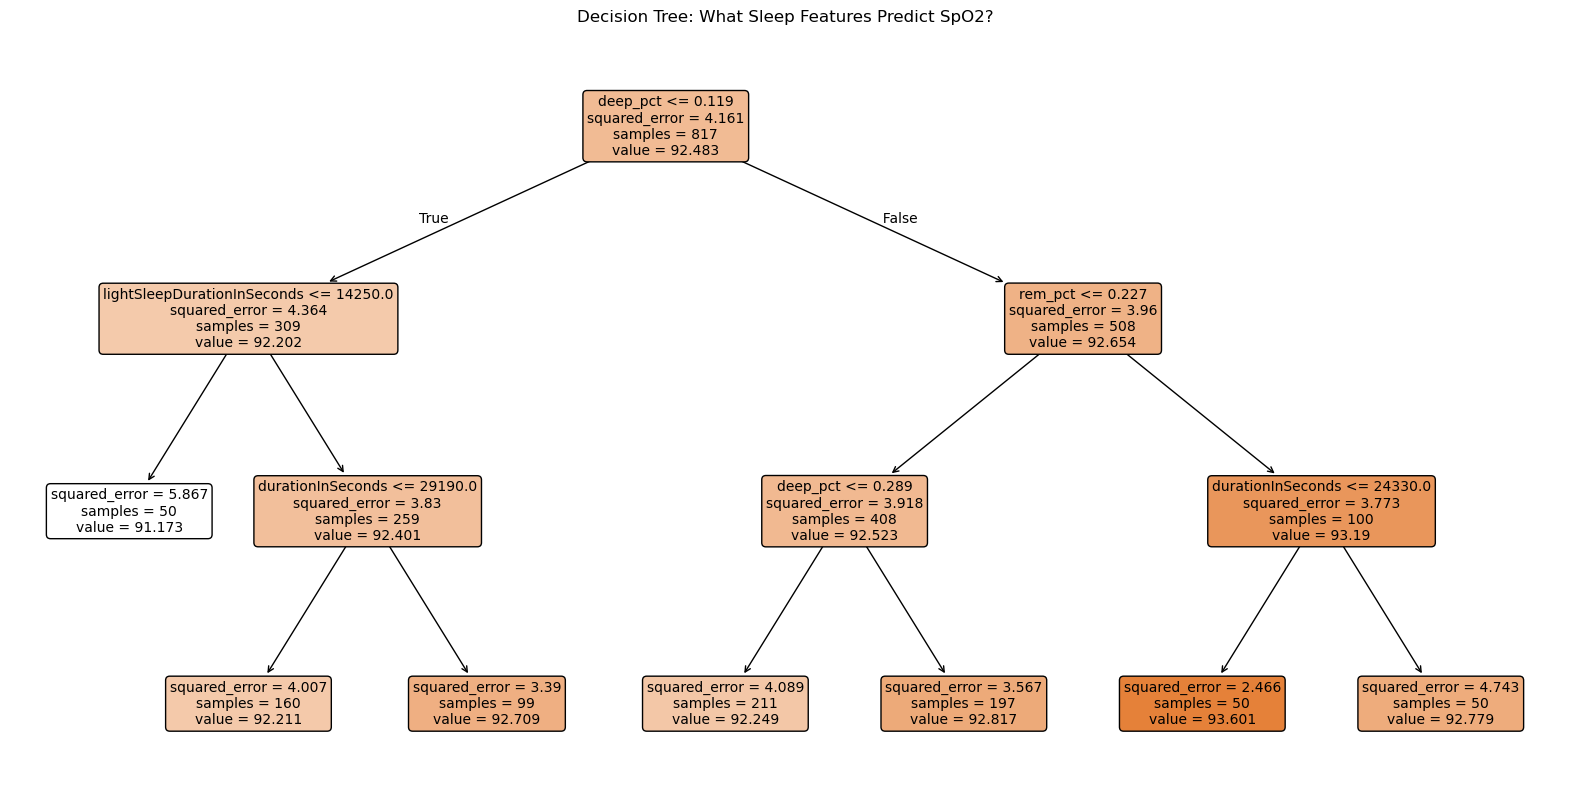

In [92]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

# 1. 設定 X (特徵) 和 y (目標 SpO2)
features = ['deep_pct', 'rem_pct', 'lightSleepDurationInSeconds', 'durationInSeconds']
X = df_final_clean[features]
y = df_final_clean['avg_spo2']

# 2. 訓練決策樹 
tree_model = DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=42)
tree_model.fit(X, y)

# 3. 畫出這棵樹
plt.figure(figsize=(20, 10))
plot_tree(tree_model, feature_names=features, filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree: What Sleep Features Predict SpO2?')
plt.show()